# Hello, MIM API

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ceos-capabilities/examples/blob/main/hello-mim-api.ipynb)

A first look at the **EO Capabilities Explorer API**: the read-only web API over the
CEOS Missions, Instruments and Measurements (MIM) Database, the same data the
Explorer site shows.

In ten short steps this notebook downloads the canonical-identifier registry,
counts what is in it, resolves a familiar nickname ("L8") to its canonical
mission, fetches that mission and its instruments, and checks which registry
edition you are reading.

**Licence.** The data are licensed CC BY 4.0. Attribution:
*"CEOS MIM Database, https://database.eohandbook.com"*.

**Rate limit.** Anonymous use is limited per IP address. A free API key raises the
limit: see the API page on the Explorer site (`/api`). The key is optional and
nothing below needs one.

Requirements: `requests`, `pandas`, `matplotlib` (all preinstalled on Colab).

## 1. Settings

The only place the address lives. Point `BASE_URL` at another deployment to repoint
the whole notebook. If you have a key, set the `MIM_API_KEY` environment variable
(never paste a key into a notebook you share).

In [1]:
import os

BASE_URL = "https://ceos-capabilities.org/api"
API_KEY = os.environ.get("MIM_API_KEY")  # optional

HEADERS = {"X-API-Key": API_KEY} if API_KEY else {}

In [2]:
import io

import matplotlib.pyplot as plt
import pandas as pd
import requests

session = requests.Session()
session.headers.update(HEADERS)


def get(path, **params):
    """GET BASE_URL + path; raise on HTTP errors with a readable message."""
    r = session.get(f"{BASE_URL}{path}", params=params or None, timeout=60)
    if r.status_code == 429:
        raise RuntimeError(f"Rate limited; retry after {r.headers.get('Retry-After', '?')} s "
                           "or use a free API key")
    if r.status_code >= 400:
        try:
            detail = r.json().get("detail")
        except ValueError:
            detail = None
        if detail:
            raise RuntimeError(f"{r.status_code} from {path}: {detail}")
    r.raise_for_status()
    return r

/private/tmp/claude-501/-Users-georgedyke-GitHub-eo-gos/e0dccb86-2e3b-43ba-8cb7-9e30705a6211/scratchpad/nbenv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## 2. Download the identifier registry as CSV

`/identifiers` is the canonical-names registry: one canonical slug per mission,
instrument, measurement and so on, plus every alias. `?format=csv` returns a flat
table that pandas reads directly.

In [3]:
resp = get("/identifiers", format="csv")
ids = pd.read_csv(io.StringIO(resp.text))
print(f"{len(ids):,} rows, {ids['entity_type'].nunique()} object types")
ids.head()

3,951 rows, 9 object types


,entity_type,entity_id,kind,value,slug,is_canonical,reason,source,source_id,minted_at,demoted_at,superseded_by,full_name,acronym,flat_id,hierarchical_id,url
0,instrument,211,slug,174-k,174-k,True,bare,mint,NaN,2026-07-24T04:10:59Z,NaN,NaN,Temperature and Humidity Profiler,174-K,instrument_174-k,instruments/174-k,/instruments/174-k
1,instrument,2262,slug,3d-sar,3d-sar,True,bare,mint,NaN,2026-07-24T04:10:59Z,NaN,NaN,3D-SAR,3D-SAR,instrument_3d-sar,instruments/3d-sar,/instruments/3d-sar
2,instrument,1627,slug,3mi,3mi,True,bare,mint,NaN,2026-07-24T04:10:59Z,NaN,NaN,Multi-Viewing Multi-Channel Multi-Polarisation...,3MI,instrument_3mi,instruments/3mi,/instruments/3mi
3,instrument,154,slug,a-dcs3,a-dcs3,True,bare,mint,NaN,2026-07-24T04:10:59Z,NaN,NaN,Argos Advanced Data Collection System3,A-DCS3,instrument_a-dcs3,instruments/a-dcs3,/instruments/a-dcs3
4,instrument,694,slug,a-dcs4,a-dcs4,True,bare,mint,NaN,2026-07-24T04:10:59Z,NaN,NaN,A-DCS4,A-DCS4,instrument_a-dcs4,instruments/a-dcs4,/instruments/a-dcs4


## 3. Count by object type

Each entity has exactly one canonical row (`is_canonical == True`); the other rows
are aliases and hierarchical ids.

In [4]:
canonical = ids[ids["is_canonical"]]
counts = canonical["entity_type"].value_counts().sort_values()
counts.to_frame("entities")

,entities
entity_type,
programme,1
constellation,9
horizon,13
measurement,29
series,85
measurement_variable,231
agency,399
mission,1222
instrument,1327


## 4. One chart: entities per object type

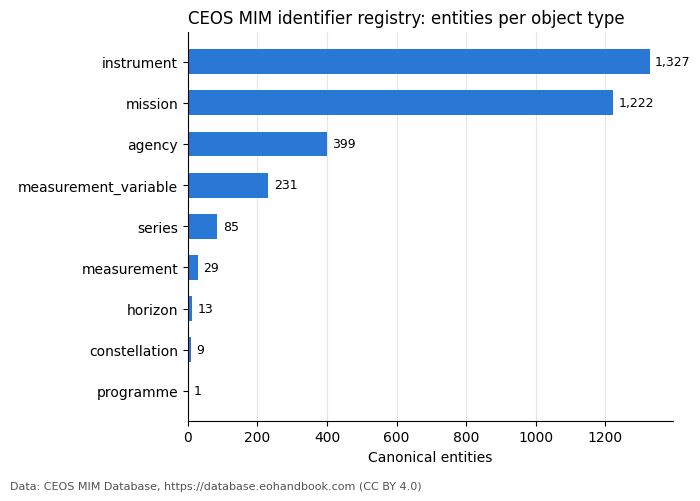

In [5]:
fig, ax = plt.subplots(figsize=(7, 0.45 * len(counts) + 0.8))
bars = ax.barh(counts.index, counts.values, color="#2a78d6", height=0.6)
ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values], padding=4, fontsize=9)
ax.set_xlabel("Canonical entities")
ax.set_title("CEOS MIM identifier registry: entities per object type", loc="left")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.grid(axis="x", color="#e6e6e3", linewidth=0.8)
ax.set_axisbelow(True)
fig.text(0.01, -0.02, "Data: CEOS MIM Database, https://database.eohandbook.com (CC BY 4.0)",
         fontsize=8, color="#52514e")
plt.tight_layout()
plt.show()

## 5. Resolve a nickname

Any alias resolves. `/mission/{alias}/identifiers` returns the canonical slug, the
numeric id and the full list of known names. Try `"Sentinel-1A"` or a numeric id.

In [6]:
ALIAS = "L8"

names = get(f"/mission/{ALIAS}/identifiers").json()
slug = names["canonical"]["slug"]
mission_id = names["entity_id"]
print(f"{ALIAS!r} -> canonical slug {slug!r}, mission id {mission_id}")
print("Also known as:", ", ".join(a["value"] for a in names["aliases"]))

'L8' -> canonical slug 'landsat-8', mission id 547
Also known as: Landsat-8, Landsat Data Continuity Mission (LDCM), L8


## 6. Fetch the mission

`/mission/{slug-or-id}` returns the mission record: names, status, dates, orbit,
lead agency, links.

In [7]:
mission = get(f"/mission/{slug}").json()
pd.Series({k: mission.get(k) for k in (
    "full_name", "mission_acronym", "status", "lead_agency",
    "launch_date", "eol_date", "orbit_type", "orbit_altitude_km", "slug",
)}).to_frame("value")

,value
full_name,Landsat 8
mission_acronym,Landsat 8
status,Operational (nominal)
lead_agency,USGS
launch_date,2013-02-11
eol_date,2030-12-31
orbit_type,Sun-synchronous
orbit_altitude_km,705
slug,landsat-8


## 7. List its instruments

In [8]:
instruments = get(f"/mission/{mission_id}/instruments").json()["instruments"]
# Explicit columns, so a mission with no instruments gives an empty table, not a KeyError.
pd.DataFrame(instruments, columns=["instrument_acronym", "full_name", "types"])

,instrument_acronym,full_name,types
0,OLI,Operational Land Imager,[Imaging multi-spectral radiometers (vis/IR)]
1,TIRS,Thermal Infrared Sensor,[Imaging multi-spectral radiometers (vis/IR)]


## 8. Which edition am I reading?

The registry carries an edition id: a content hash served as the HTTP `ETag`.
The same ETag means the same registry; a new edition gets a new ETag. Cite it
(the first eight hex characters are the short form) when you publish results.

In [9]:
etag = resp.headers["ETag"].strip('"')
print("ETag:         ", etag)
print("Short edition:", etag.split(":")[-1][:8])

ETag:          sha256:d302609f47a73f517c5b09ba7823c6311144417de4dbb5c43fd89ce10cdae6d2
Short edition: d302609f


## 9. Cheap drift check

A `HEAD` request returns the headers without the 0.8 MB body, so a script can check
for a new edition before downloading anything.

In [10]:
head = session.head(f"{BASE_URL}/identifiers", params={"format": "csv"}, timeout=60)
if head.ok:
    same = head.headers.get("ETag", "").strip('"') == etag
    print("Edition unchanged" if same else "New edition published: download again")
else:
    print(f"HEAD returned {head.status_code}; compare the ETag of a fresh GET instead")

Edition unchanged


## 10. Licence, from the API itself

Every data response carries the licence as an RFC 8288 `Link` header, so even a
client that never reads a body sees the terms.

In [11]:
print(resp.headers.get("Link"))

<https://creativecommons.org/licenses/by/4.0/>; rel="license"
